# 🛡️ DeepDetect AI — Deepfake Video Detection
### End-to-End Pipeline: Video Preprocessing, Face Extraction, ResNet-18 + Bidirectional LSTM, Evaluation, and Deployment

## 📖 Overview

This notebook uses the same model architecture and preprocessing pipeline used by the deployed application.

1. **Video preprocessing**
   - Uniform temporal frame extraction.
   - Haar Cascade face detection.
   - Face cropping with a 20% margin.
   - Resize to 224 × 224.
   - ImageNet normalization.

2. **Spatial-temporal model**
   - **ResNet-18** extracts spatial features from each face frame.
   - A **512-dimensional projection** prepares the features for sequence modeling.
   - A **Bidirectional LSTM** models temporal relationships across frames.
   - A frame-level head produces per-frame anomaly logits.
   - A video-level head produces the final Real/Fake logit.

3. **Evaluation and deployment**
   - Training and validation curves.
   - Confusion matrix.
   - Classification report.
   - ROC-AUC.
   - Single-video forensic inference.
   - The resulting `deepfake_model.pt` is compatible with the Streamlit application.


## 📦 Step 1: Install & Import Dependencies

The notebook uses the same project modules as the application so that preprocessing, model architecture, and inference remain consistent.


In [1]:
import os
import sys
import glob
import random
import numpy as np
import pandas as pd
import cv2
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, WeightedRandomSampler
import torchvision.transforms as transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_curve,
    auc,
    roc_auc_score
)

PROJECT_ROOT = os.path.abspath(os.getcwd())
if os.path.basename(PROJECT_ROOT).lower() == "notebooks":
    PROJECT_ROOT = os.path.dirname(PROJECT_ROOT)

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.model import ResNeXtLSTMDetector
from src.preprocessing import (
    process_video,
    DeepfakeVideoDataset,
    train_transform,
    test_transform
)
from src.inference import predict_video

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Project root: {PROJECT_ROOT}")
print(f"Using compute device: {device}")
print("Backbone: ResNet-18")


Project root: c:\Users\Nishant\OneDrive\Documents\deep_detect
Using compute device: cpu
Backbone: ResNet-18


## 📁 Step 2: Dataset Discovery & Class Balancing

The dataset uses:
- `Celeb-real` and `YouTube-real` as Real (`0`)
- `Celeb-synthesis` as Fake (`1`)

A balanced subset is created before the stratified train/test split.


In [2]:
DATA_DIR = os.path.join(PROJECT_ROOT, "data")

celeb_real = glob.glob(
    os.path.join(DATA_DIR, "Celeb-real", "*.mp4")
)
yt_real = glob.glob(
    os.path.join(DATA_DIR, "YouTube-real", "*.mp4")
)
all_real_videos = celeb_real + yt_real

all_fake_videos = glob.glob(
    os.path.join(DATA_DIR, "Celeb-synthesis", "*.mp4")
)

print(
    f"Total Real Videos Found: {len(all_real_videos)} "
    f"(Celeb-real: {len(celeb_real)}, YouTube-real: {len(yt_real)})"
)
print(f"Total Fake Videos Found: {len(all_fake_videos)}")

SAMPLE_REAL_COUNT = min(100, len(all_real_videos))
SAMPLE_FAKE_COUNT = min(100, len(all_fake_videos))

sampled_real = random.sample(
    all_real_videos,
    SAMPLE_REAL_COUNT
)
sampled_fake = random.sample(
    all_fake_videos,
    SAMPLE_FAKE_COUNT
)

dataset_items = (
    [(path, 0) for path in sampled_real]
    + [(path, 1) for path in sampled_fake]
)

random.shuffle(dataset_items)

print(
    f"Balanced dataset: {len(dataset_items)} videos | "
    f"Real: {SAMPLE_REAL_COUNT} | Fake: {SAMPLE_FAKE_COUNT}"
)


Total Real Videos Found: 890 (Celeb-real: 590, YouTube-real: 300)
Total Fake Videos Found: 5639
Balanced dataset: 200 videos | Real: 100 | Fake: 100


## ✂️ Step 3: Video Frame Splitting & Face Extraction

The notebook uses the project's production preprocessing module.

For each video:
1. Uniformly sample 16 frames.
2. Detect the primary face using Haar Cascade.
3. Add a 20% bounding-box margin.
4. Resize the cropped face to 224 × 224.
5. Convert the sequence into the format required by the CNN + LSTM model.


Sample Video: c:\Users\Nishant\OneDrive\Documents\deep_detect\data\YouTube-real\00249.mp4
Label: Real (Authentic)
Sequence shape: (8, 224, 224, 3)


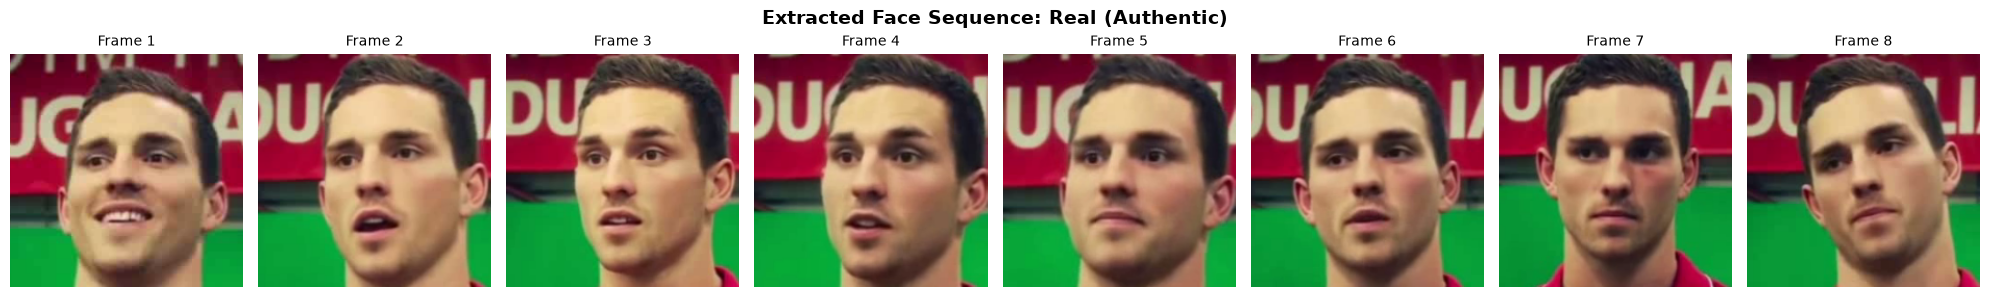

In [3]:
sample_path, sample_label = dataset_items[0]

sample_label_name = (
    "Fake (Synthetic)"
    if sample_label == 1
    else "Real (Authentic)"
)

sample_faces, sample_pil = process_video(
    sample_path,
    num_frames=8
)

print(
    f"Sample Video: {sample_path}"
)
print(
    f"Label: {sample_label_name}"
)
print(
    f"Sequence shape: {sample_faces.shape}"
)

fig, axes = plt.subplots(
    1,
    8,
    figsize=(20, 3)
)

for i in range(8):
    axes[i].imshow(sample_faces[i])
    axes[i].set_title(
        f"Frame {i + 1}",
        fontsize=10
    )
    axes[i].axis("off")

plt.suptitle(
    f"Extracted Face Sequence: {sample_label_name}",
    fontsize=14,
    fontweight="bold"
)
plt.tight_layout()
plt.show()


## 🗂️ Step 4: PyTorch Dataset & DataLoader Pipeline

The training and evaluation datasets use the same `DeepfakeVideoDataset` implementation as the project.

- Training uses augmentation.
- Evaluation uses clean ImageNet normalization.
- Each video produces a `(16, 3, 224, 224)` tensor.
- Labels are `0.0` for Real and `1.0` for Fake.


In [4]:
NUM_FRAMES = 16
BATCH_SIZE = 4

train_items, test_items = train_test_split(
    dataset_items,
    test_size=0.2,
    random_state=SEED,
    stratify=[item[1] for item in dataset_items]
)

train_dataset = DeepfakeVideoDataset(
    train_items,
    num_frames=NUM_FRAMES,
    is_training=True
)

test_dataset = DeepfakeVideoDataset(
    test_items,
    num_frames=NUM_FRAMES,
    is_training=False
)

train_labels = [
    int(label)
    for _, label in train_items
]

class_counts = {
    0: train_labels.count(0),
    1: train_labels.count(1)
}

if class_counts[0] > 0 and class_counts[1] > 0:
    sample_weights = [
        1.0 / class_counts[label]
        for label in train_labels
    ]

    sampler = WeightedRandomSampler(
        sample_weights,
        num_samples=len(sample_weights),
        replacement=True
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        sampler=sampler,
        num_workers=0
    )

    print(
        f"Weighted sampler enabled: {class_counts}"
    )
else:
    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0
    )

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print(
    f"Train samples: {len(train_dataset)} | "
    f"Test samples: {len(test_dataset)}"
)
print(
    f"Training labels: {class_counts}"
)


Weighted sampler enabled: {0: 80, 1: 80}
Train samples: 160 | Test samples: 40
Training labels: {0: 80, 1: 80}


## 🧠 Step 5: Deep Learning Architecture — ResNet-18 + Bidirectional LSTM

The deployment checkpoint must be loaded with the exact architecture used during training.

### Spatial feature extraction
ResNet-18 converts each 224 × 224 face frame into a 512-dimensional CNN representation.

### Feature projection
The CNN representation is passed through a linear projection, BatchNorm, ReLU, and dropout.

### Temporal modeling
A two-layer Bidirectional LSTM processes the 16-frame feature sequence.

### Dual output
- Frame-level classifier: one anomaly logit per frame.
- Video-level classifier: one final binary classification logit.


In [5]:
model = ResNeXtLSTMDetector(
    backbone_type="resnet18",
    hidden_dim=256,
    num_layers=2,
    bidirectional=True,
    dropout=0.4,
    pretrained=True
)

model = model.to(device)

print(model)
print()
print("Backbone:", model.backbone_type)
print("Device:", device)


ResNeXtLSTMDetector(
  (feature_extractor): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNor

## 🏋️ Step 6: Training & Validation

Training is configured to match the project's current training strategy:

- ResNet-18 backbone.
- First freeze the CNN backbone so the temporal/classification heads learn stable representations.
- Unfreeze after the freeze period for fine-tuning.
- `BCEWithLogitsLoss`.
- AdamW optimizer.
- Cosine annealing learning-rate scheduler.
- Gradient clipping.
- Best checkpoint selected using validation loss.
- Early stopping.


In [6]:
EPOCHS = 5
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-3
FREEZE_EPOCHS = 2
PATIENCE = 3

pos_weight_value = (
    class_counts[0] / class_counts[1]
    if class_counts[1] > 0
    else 1.0
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [pos_weight_value],
        dtype=torch.float32,
        device=device
    )
)

model.freeze_backbone()

optimizer = torch.optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

MODEL_SAVE_PATH = os.path.join(
    PROJECT_ROOT,
    "deepfake_model.pt"
)

best_val_loss = float("inf")
best_val_acc = 0.0
epochs_without_improvement = 0
best_model_state = None

print("--- Starting Training ---")

for epoch in range(1, EPOCHS + 1):

    if epoch == FREEZE_EPOCHS + 1:

        model.unfreeze_backbone()

        optimizer = torch.optim.AdamW(
            [
                {
                    "params": model.feature_extractor.parameters(),
                    "lr": LEARNING_RATE * 0.1
                },
                {
                    "params": model.feature_proj.parameters()
                },
                {
                    "params": model.lstm.parameters()
                },
                {
                    "params": model.frame_classifier.parameters()
                },
                {
                    "params": model.classifier.parameters()
                }
            ],
            lr=LEARNING_RATE,
            weight_decay=WEIGHT_DECAY
        )

        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=max(EPOCHS - FREEZE_EPOCHS, 1)
        )

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for videos, labels in train_loader:

        videos = videos.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits, _ = model(videos)
        logits = logits.squeeze(1)

        loss = criterion(
            logits,
            labels
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += (
            loss.item()
            * videos.size(0)
        )

        preds = (
            torch.sigmoid(logits)
            >= 0.5
        ).float()

        correct += (
            preds == labels
        ).sum().item()

        total += labels.size(0)

    scheduler.step()

    train_loss = (
        running_loss / max(total, 1)
    )

    train_acc = (
        correct / max(total, 1)
    )

    model.eval()

    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for videos, labels in test_loader:

            videos = videos.to(device)
            labels = labels.to(device)

            logits, _ = model(videos)
            logits = logits.squeeze(1)

            loss = criterion(
                logits,
                labels
            )

            val_loss_total += (
                loss.item()
                * videos.size(0)
            )

            preds = (
                torch.sigmoid(logits)
                >= 0.5
            ).float()

            val_correct += (
                preds == labels
            ).sum().item()

            val_total += labels.size(0)

    val_loss = (
        val_loss_total
        / max(val_total, 1)
    )

    val_acc = (
        val_correct
        / max(val_total, 1)
    )

    history["train_loss"].append(
        train_loss
    )
    history["train_acc"].append(
        train_acc
    )
    history["val_loss"].append(
        val_loss
    )
    history["val_acc"].append(
        val_acc
    )

    print(
        f"Epoch [{epoch}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc * 100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc * 100:.2f}%"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_val_acc = val_acc
        epochs_without_improvement = 0

        best_model_state = {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        }

        torch.save(
            model.state_dict(),
            MODEL_SAVE_PATH
        )

        print(
            f"  -> Best checkpoint saved: "
            f"{MODEL_SAVE_PATH}"
        )

    else:

        epochs_without_improvement += 1

        print(
            f"  -> No improvement for "
            f"{epochs_without_improvement} epoch(s)"
        )

    if epochs_without_improvement >= PATIENCE:

        print(
            f"Early stopping at epoch {epoch}"
        )
        break

if best_model_state is not None:

    model.load_state_dict(
        best_model_state
    )

print()
print(
    f"Best validation loss: {best_val_loss:.4f}"
)
print(
    f"Best validation accuracy: "
    f"{best_val_acc * 100:.2f}%"
)
print(
    f"Checkpoint: {MODEL_SAVE_PATH}"
)


--- Starting Training ---
Epoch [1/5] Train Loss: 0.6951 | Train Acc: 43.75% | Val Loss: 0.6930 | Val Acc: 50.00%
  -> Best checkpoint saved: c:\Users\Nishant\OneDrive\Documents\deep_detect\deepfake_model.pt
Epoch [2/5] Train Loss: 0.6908 | Train Acc: 48.75% | Val Loss: 0.6871 | Val Acc: 62.50%
  -> Best checkpoint saved: c:\Users\Nishant\OneDrive\Documents\deep_detect\deepfake_model.pt
Epoch [3/5] Train Loss: 0.6817 | Train Acc: 57.50% | Val Loss: 0.6736 | Val Acc: 57.50%
  -> Best checkpoint saved: c:\Users\Nishant\OneDrive\Documents\deep_detect\deepfake_model.pt
Epoch [4/5] Train Loss: 0.6395 | Train Acc: 67.50% | Val Loss: 0.6336 | Val Acc: 65.00%
  -> Best checkpoint saved: c:\Users\Nishant\OneDrive\Documents\deep_detect\deepfake_model.pt
Epoch [5/5] Train Loss: 0.5825 | Train Acc: 74.38% | Val Loss: 0.6118 | Val Acc: 70.00%
  -> Best checkpoint saved: c:\Users\Nishant\OneDrive\Documents\deep_detect\deepfake_model.pt

Best validation loss: 0.6118
Best validation accuracy: 70.00%
C

## 📊 Step 7: Evaluation, Confusion Matrix & ROC-AUC

The saved checkpoint is reloaded using the same ResNet-18 architecture.

Evaluation includes:
- Training/validation loss.
- Training/validation accuracy.
- Confusion matrix.
- Classification report.
- ROC-AUC.
- ROC curve.


In [7]:
model.load_state_dict(
    torch.load(
        MODEL_SAVE_PATH,
        map_location=device,
        weights_only=True
    )
)

model = model.to(device)
model.eval()

all_probs = []
all_preds = []
all_labels = []

with torch.no_grad():

    for videos, labels in test_loader:

        videos = videos.to(device)

        logits, _ = model(videos)

        probs = (
            torch.sigmoid(
                logits.squeeze(1)
            )
            .cpu()
            .numpy()
        )

        preds = (
            probs >= 0.5
        ).astype(int)

        all_probs.extend(
            probs.tolist()
        )

        all_preds.extend(
            preds.tolist()
        )

        all_labels.extend(
            labels.numpy()
            .astype(int)
            .tolist()
        )

all_probs = np.asarray(all_probs)
all_preds = np.asarray(all_preds)
all_labels = np.asarray(all_labels)

cm = confusion_matrix(
    all_labels,
    all_preds,
    labels=[0, 1]
)

print("--- Confusion Matrix ---")
print(cm)

print()
print("--- Classification Report ---")
print(
    classification_report(
        all_labels,
        all_preds,
        target_names=[
            "Real (Authentic)",
            "Fake (Deepfake)"
        ],
        zero_division=0
    )
)

if len(np.unique(all_labels)) == 2:

    test_auc = roc_auc_score(
        all_labels,
        all_probs
    )

    fpr, tpr, _ = roc_curve(
        all_labels,
        all_probs
    )

    print(
        f"ROC-AUC: {test_auc:.4f}"
    )

else:

    test_auc = float("nan")
    fpr, tpr = None, None

    print(
        "ROC-AUC requires both classes in the test set."
    )


--- Confusion Matrix ---
[[10 10]
 [ 2 18]]

--- Classification Report ---
                  precision    recall  f1-score   support

Real (Authentic)       0.83      0.50      0.62        20
 Fake (Deepfake)       0.64      0.90      0.75        20

        accuracy                           0.70        40
       macro avg       0.74      0.70      0.69        40
    weighted avg       0.74      0.70      0.69        40

ROC-AUC: 0.7775


## 📈 Step 8: Training Curves & Evaluation Plots


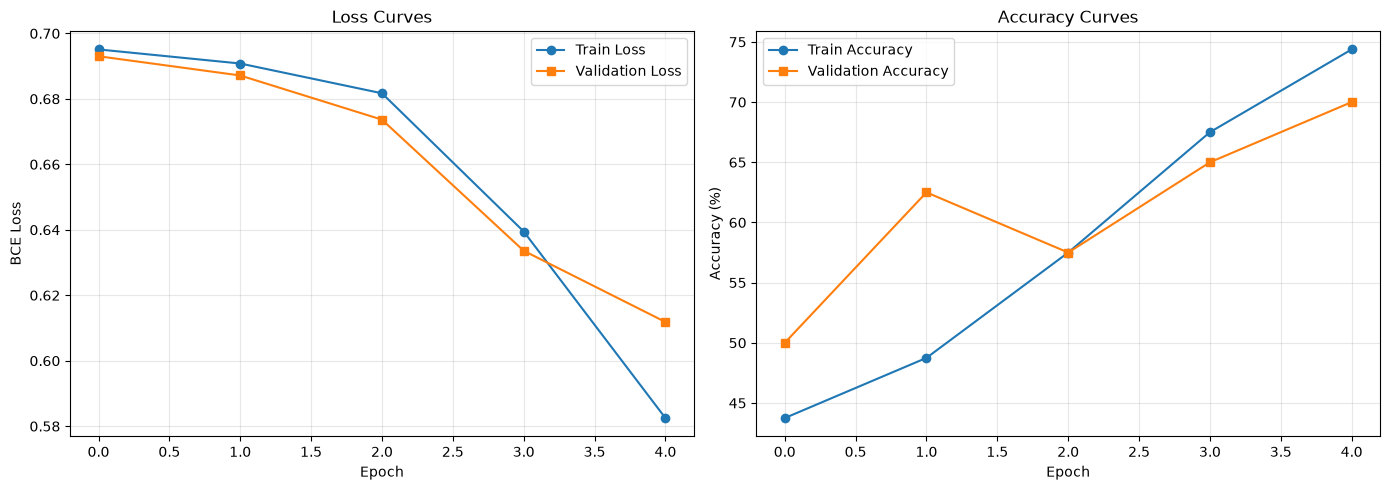

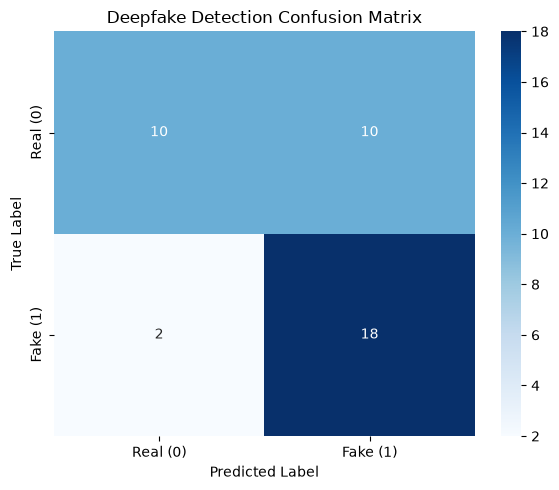

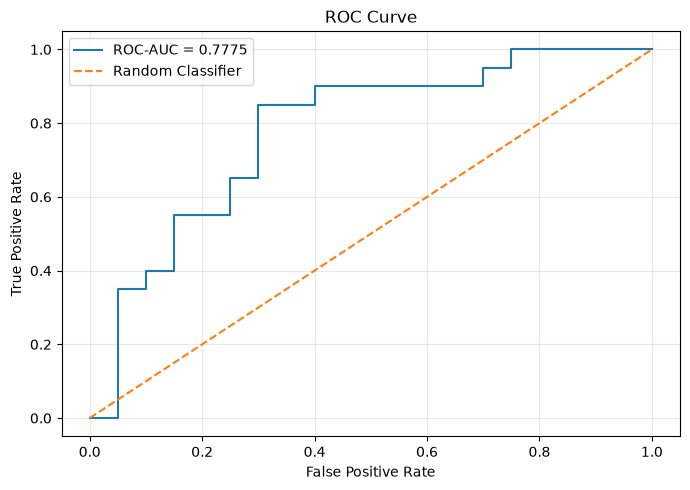

In [8]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

axes[0].plot(
    history["train_loss"],
    label="Train Loss",
    marker="o"
)

axes[0].plot(
    history["val_loss"],
    label="Validation Loss",
    marker="s"
)

axes[0].set_title(
    "Loss Curves"
)

axes[0].set_xlabel(
    "Epoch"
)

axes[0].set_ylabel(
    "BCE Loss"
)

axes[0].legend()
axes[0].grid(
    True,
    alpha=0.3
)

axes[1].plot(
    [
        value * 100
        for value in history["train_acc"]
    ],
    label="Train Accuracy",
    marker="o"
)

axes[1].plot(
    [
        value * 100
        for value in history["val_acc"]
    ],
    label="Validation Accuracy",
    marker="s"
)

axes[1].set_title(
    "Accuracy Curves"
)

axes[1].set_xlabel(
    "Epoch"
)

axes[1].set_ylabel(
    "Accuracy (%)"
)

axes[1].legend()
axes[1].grid(
    True,
    alpha=0.3
)

plt.tight_layout()
plt.show()


plt.figure(
    figsize=(6, 5)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Real (0)",
        "Fake (1)"
    ],
    yticklabels=[
        "Real (0)",
        "Fake (1)"
    ]
)

plt.title(
    "Deepfake Detection Confusion Matrix"
)

plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.tight_layout()

CONFUSION_PATH = os.path.join(
    PROJECT_ROOT,
    "confusion_matrix.png"
)

plt.savefig(
    CONFUSION_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

if fpr is not None:

    plt.figure(
        figsize=(7, 5)
    )

    plt.plot(
        fpr,
        tpr,
        label=f"ROC-AUC = {test_auc:.4f}"
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Random Classifier"
    )

    plt.xlabel(
        "False Positive Rate"
    )

    plt.ylabel(
        "True Positive Rate"
    )

    plt.title(
        "ROC Curve"
    )

    plt.legend()
    plt.grid(
        True,
        alpha=0.3
    )

    plt.tight_layout()
    plt.show()


## 🔮 Step 9: Single Video Inference & Temporal Anomaly Analysis

For inference, the notebook calls the same `predict_video()` function used by the application.

This guarantees:
- The same ResNet-18 checkpoint.
- The same ImageNet normalization.
- The same face extraction pipeline.
- The same 16-frame temporal sequence.
- The same Real/Fake threshold of 0.5.


Testing forensic inference on: c:\Users\Nishant\OneDrive\Documents\deep_detect\data\Celeb-real\id13_0008.mp4

FORENSIC VERDICT: FAKE
Confidence: 54.53%
Deepfake Probability: 54.53%
Real Probability: 45.47%


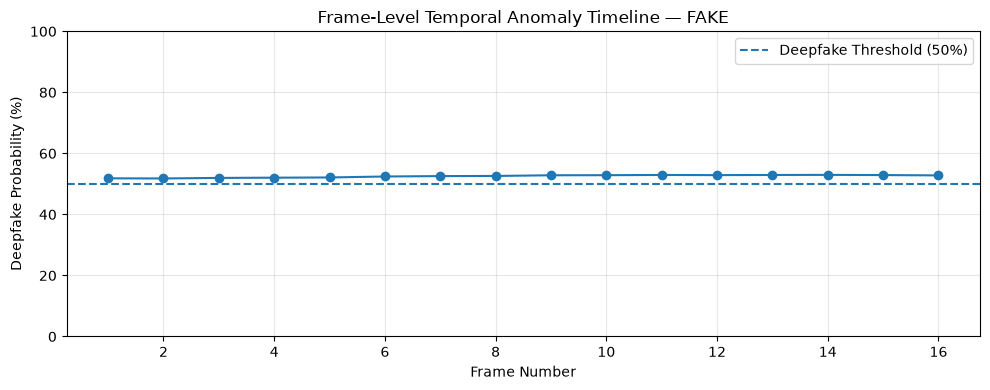

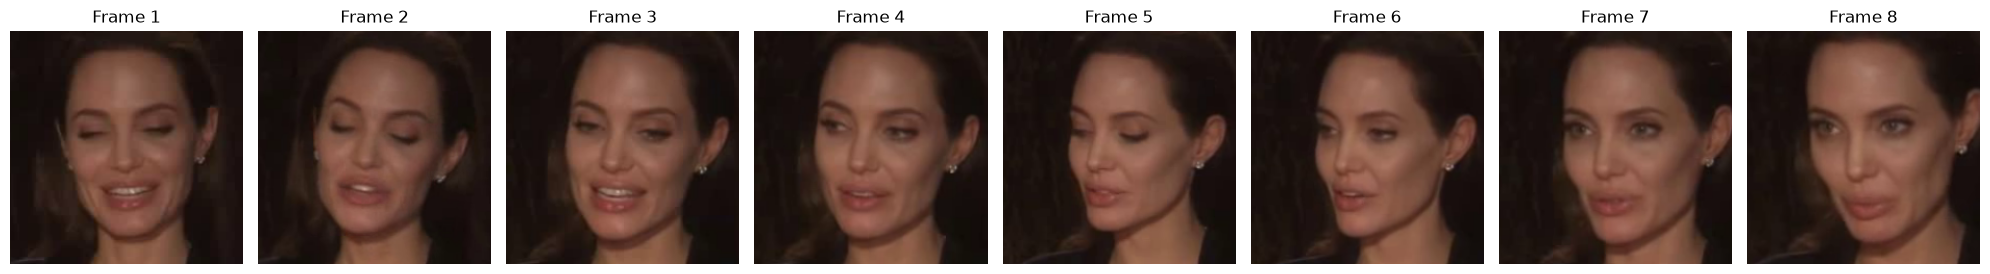

In [9]:
test_sample_video = test_items[0][0]

print(
    f"Testing forensic inference on: "
    f"{test_sample_video}"
)

result = predict_video(
    video_path=test_sample_video,
    model=model,
    device=device,
    num_frames=NUM_FRAMES,
    backbone_type="resnet18"
)

print()
print("=" * 60)
print(
    f"FORENSIC VERDICT: {result['verdict']}"
)
print(
    f"Confidence: {result['confidence']:.2f}%"
)
print(
    f"Deepfake Probability: "
    f"{result['fake_probability'] * 100:.2f}%"
)
print(
    f"Real Probability: "
    f"{result['real_probability'] * 100:.2f}%"
)
print("=" * 60)

frame_probs = result[
    "frame_probabilities"
]

plt.figure(
    figsize=(10, 4)
)

plt.plot(
    range(1, len(frame_probs) + 1),
    [
        p * 100
        for p in frame_probs
    ],
    marker="o"
)

plt.axhline(
    50,
    linestyle="--",
    label="Deepfake Threshold (50%)"
)

plt.title(
    f"Frame-Level Temporal Anomaly Timeline — "
    f"{result['verdict']}"
)

plt.xlabel(
    "Frame Number"
)

plt.ylabel(
    "Deepfake Probability (%)"
)

plt.ylim(
    0,
    100
)

plt.legend()
plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()
plt.show()

face_frames = result["face_frames"]

if face_frames:

    columns = min(
        8,
        len(face_frames)
    )

    fig, axes = plt.subplots(
        1,
        columns,
        figsize=(20, 3)
    )

    if columns == 1:
        axes = [axes]

    for i in range(columns):

        axes[i].imshow(
            face_frames[i]
        )

        axes[i].set_title(
            f"Frame {i + 1}"
        )

        axes[i].axis("off")

    plt.tight_layout()
    plt.show()


## 🚀 Step 10: Streamlit Web Application

The trained checkpoint is used by the Streamlit application with **ResNet-18 + Bidirectional LSTM**.

Run the application from the project root:

```bash
streamlit run app.py
```

### Application configuration

The current application is intentionally locked to:

- **Backbone:** ResNet-18
- **Temporal model:** Bidirectional LSTM
- **Sequence length:** 16 frames by default
- **Input:** 224 × 224 face crops
- **Checkpoint:** `deepfake_model.pt`

The application should not select ResNeXt-50 or ResNet-50 when using this checkpoint because the checkpoint architecture must exactly match the model used to create it.
